# Task 3 – Bộ ảnh chuỗi chữ số viết tay: khám phá dữ liệu

Notebook này mô tả bộ dữ liệu dùng cho Task 3 (mục 3.1 của báo cáo). Mô hình nằm ở notebook `05_task3_model.ipynb`.

**Nguồn gốc dữ liệu.** Nhóm tự sinh ảnh bằng kỹ thuật *data synthesis* (chương 5.3): ghép 3–8 ảnh chữ số đơn của MNIST (LeCun và cộng sự, 1998) thành một dãy nằm ngang, trong đó **mọi chữ số của một ảnh đều do cùng một người viết**, giống một dãy số viết tay thật. Mỗi mẫu gồm một ảnh và chuỗi chữ số tương ứng, ví dụ ảnh → `"20369"`.

- **MNIST gốc:** https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz (60.000 ảnh train, 10.000 ảnh test, 28 × 28).
- **Mã người viết:** MNIST không cho biết ai viết chữ số nào. Bộ QMNIST (Yadav và Bottou, 2019; https://github.com/facebookresearch/qmnist) đã truy từng ảnh MNIST về tờ mẫu gốc trong cơ sở dữ liệu NIST Special Database 19 và công bố mã người viết của từng ảnh. Ảnh QMNIST-train khớp từng ảnh và đúng thứ tự với MNIST-train; 10.000 ảnh đầu của QMNIST-test khớp với MNIST-test. Nhóm dùng cột mã người viết này để ghép chuỗi.
- **Script:** `FinalDeepData/task3/generate_data_v3.py` sinh bộ ảnh (seed cố định nên chạy lại ra đúng bộ này); `check_writers.py` kiểm tra lại mỗi ảnh có chữ của bao nhiêu người viết.
- **Các phiên bản:**
  - v1 và v2 là hai bản đầu của nhóm. Mỗi chữ số được lấy từ một ảnh MNIST bất kỳ, nên một chuỗi là chữ của nhiều người. `check_writers.py` chạy lại hai script cũ với đúng seed và cho thấy: ở cả hai bản, 0/24.000 ảnh có mọi chữ số cùng một người viết; trung bình mỗi ảnh có chữ của 5,5 người.
  - **v3 (bộ chính)** sửa lại theo góp ý của giảng viên: mỗi ảnh chỉ ghép chữ số của một người viết; kiểu chữ (cỡ chữ, độ nghiêng, độ dày nét, khoảng cách) chọn một lần cho cả chuỗi; train và validation dùng hai nhóm người viết khác nhau. Các biến đổi ảnh khác giữ như v2: chữ số sát hoặc chồng nhẹ, xoay, nghiêng, mờ, đổi độ đậm nét.
  - **Mô hình được huấn luyện trên v3.** Bộ v2 chỉ còn dùng ở notebook 05 để so sánh.

Notebook chạy được cả trên máy lẫn Google Colab. Trên Colab, tải `FinalDeepData_hoan_chinh.zip` lên rồi bỏ dấu `#` ở dòng `!unzip` bên dưới. Nếu chưa có thư mục `mnist_sequences_v3`, ô đầu tiên tự sinh bộ ảnh (khoảng 20 giây, cần mạng để tải nhãn QMNIST lần đầu).

In [1]:
# !unzip -q FinalDeepData_hoan_chinh.zip      # chỉ cần trên Colab

import os, sys, json, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_ROOT = "FinalDeepData"
sys.path.append(os.path.join(DATA_ROOT, "common"))
sys.path.append(os.path.join(DATA_ROOT, "task3"))
from data_utils import load_task3, encode_labels, decode_tokens, augment, PAD, BOS, EOS, VOCAB_SIZE
import generate_data_v3 as gen3        # script sinh v3: dùng lại hàm đọc mã người viết và hàm ghép ảnh
import generate_data_v2 as gen2        # script sinh v2 (cách ghép cũ), chỉ để vẽ hình so sánh

TASK3_DIR = os.path.join(DATA_ROOT, "task3", "data")
VERSIONS = {"v3": os.path.join(TASK3_DIR, "mnist_sequences_v3"),
            "v2": os.path.join(TASK3_DIR, "mnist_sequences_v2")}
if not os.path.exists(VERSIONS["v3"]):     # chưa có bộ v3 thì sinh
    subprocess.run([sys.executable, "generate_data_v3.py"], cwd=os.path.join(DATA_ROOT, "task3"), check=True)
SPLITS = ["train", "validation", "test"]
FIG_DIR = os.path.join("task3_outputs", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# Kiểu hình: lưới mờ, bỏ viền trên/phải; màu theo thứ tự cố định
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e"})
COLORS = {"v3": "#2a78d6", "v2": "#eb6834"}

## 1. Đọc nhãn và kích thước ảnh gốc

Mỗi phiên bản có ba file nhãn `train_labels.csv`, `validation_labels.csv`, `test_labels.csv` với ba cột `image_path`, `label`, `length`. File nhãn của v3 có thêm hai cột:
- `writer`: mã người viết NIST của cả chuỗi;
- `source`: chỉ số các ảnh MNIST đã ghép, từ trái sang phải (train và validation lấy từ MNIST-train, test lấy từ MNIST-test).

Nhãn **phải đọc dạng chuỗi** (`dtype={"label": str}`): nếu để pandas tự đổi sang số, nhãn `"013204"` sẽ thành `13204` và mất số 0 ở đầu. Kích thước ảnh gốc được đọc từ phần đầu file PNG (không cần giải nén cả ảnh).

In [2]:
frames = []
for version, root in VERSIONS.items():
    for split in SPLITS:
        df = pd.read_csv(os.path.join(root, f"{split}_labels.csv"), dtype={"label": str, "source": str},
                         encoding="utf-8-sig")
        sizes = [Image.open(os.path.join(root, p)).size for p in df["image_path"]]   # (rộng, cao)
        df["width"] = [w for w, h in sizes]
        df["height"] = [h for w, h in sizes]
        df["version"], df["split"] = version, split
        frames.append(df)
meta = pd.concat(frames, ignore_index=True)
v3 = meta[meta["version"] == "v3"].copy()
v3["writer"] = v3["writer"].astype(int)          # cột chỉ có ở v3 (v2 không lưu người viết)

# Kiểm tra nhanh: nhãn chỉ gồm chữ số, độ dài khớp cột length
assert meta["label"].str.fullmatch(r"\d+").all()
assert (meta["label"].str.len() == meta["length"]).all()
v3.drop(columns="version").head()

,image_path,label,length,writer,source,width,height,split
0,train/000000.png,335790,6,2156,32044 21660 47854 54396 47874 39624,119,32,train
1,train/000001.png,094162,6,2340,45596 42118 6448 48126 24184 28544,135,32,train
2,train/000002.png,372,3,2284,21468 43710 18978,70,32,train
3,train/000003.png,45216,5,2271,32032 44106 46414 27300 4990,97,32,train
4,train/000004.png,425,3,192,41159 41181 41127,92,32,train


In [3]:
summary = (meta.groupby(["version", "split"], sort=False)
               .agg(so_anh=("label", "size"),
                    cao=("height", "max"),
                    rong_min=("width", "min"),
                    rong_max=("width", "max"),
                    do_dai_min=("length", "min"),
                    do_dai_max=("length", "max"),
                    ty_le_bat_dau_bang_0=("label", lambda s: s.str.startswith("0").mean()))
               .round(3))
display(summary)

with open(os.path.join(VERSIONS["v3"], "generation_config.json"), encoding="utf-8") as f:
    config3 = json.load(f)
print("Ảnh v3 rộng quá 256 pixel nên được thu nhỏ cho vừa:",
      {split: s["images_shrunk_to_fit_256px"] for split, s in config3["split_stats"].items()})

so_anh  cao  rong_min  rong_max  do_dai_min  do_dai_max  \
version split                                                                 
v3      train        20000   32        28       256           3           8   
        validation    2000   32        29       256           3           8   
        test          2000   32        42       256           3           8   
v2      train        20000   32        35       254           3           8   
        validation    2000   32        44       232           3           8   
        test          2000   32        43       237           3           8   

                    ty_le_bat_dau_bang_0  
version split                             
v3      train                      0.097  
        validation                 0.099  
        test                       0.112  
v2      train                      0.097  
        validation                 0.096  
        test                       0.104

Ảnh v3 rộng quá 256 pixel nên được thu nhỏ cho vừa: {'train': 56, 'validation': 7, 'test': 1}


**Nhận xét.** Mỗi phiên bản có 20.000 ảnh train, 2.000 ảnh validation và 2.000 ảnh test. Ảnh là ảnh xám (chữ trắng trên nền đen), cao 32 pixel, rộng thay đổi theo số chữ số và cỡ chữ, tối đa 256 pixel. Ở v3, cỡ chữ và khoảng cách được chọn cho cả chuỗi nên một số ít chuỗi 7–8 chữ số của người viết chữ to bị rộng quá 256 pixel; các ảnh này (56/20.000 ảnh train) được thu nhỏ cả ảnh cho vừa. Độ dài chuỗi từ 3 đến 8 và khoảng 10% nhãn bắt đầu bằng số 0, nên mô hình phải đọc được cả số 0 ở đầu.

## 2. Ảnh mẫu

Mỗi ảnh được đệm nền đen bên phải cho đủ 32 × 256 (xem mục 5). Tiêu đề ghi nhãn và mã người viết của cả chuỗi.

v3 train: (20000, 32, 256) uint8


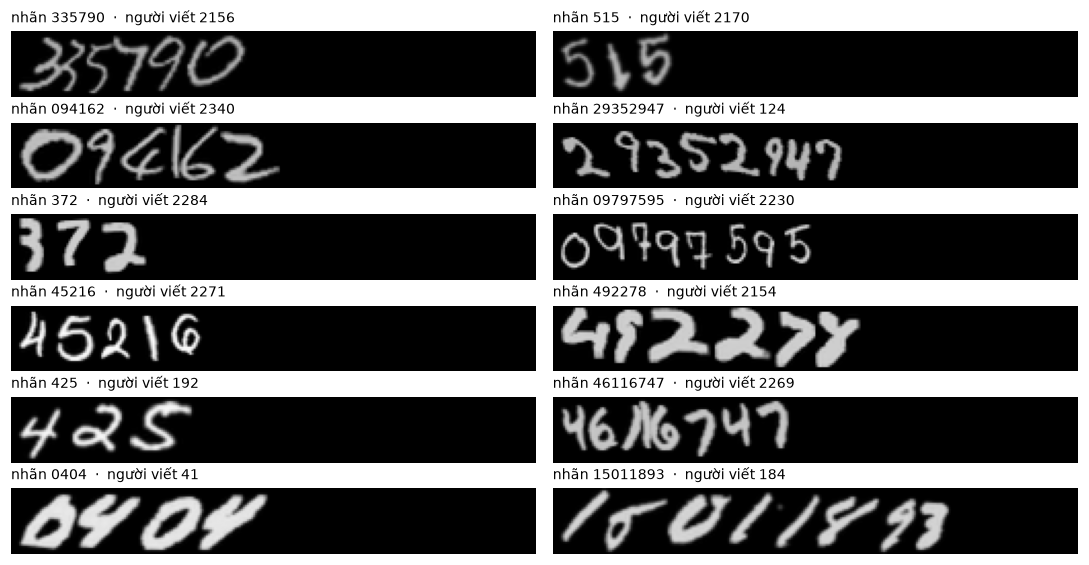

In [4]:
X3, labels3 = load_task3(VERSIONS["v3"], "train")
v3_train = v3[v3["split"] == "train"].reset_index(drop=True)
print("v3 train:", X3.shape, X3.dtype)

fig, axes = plt.subplots(6, 2, figsize=(10, 5.2))
for k, ax in enumerate(axes.T.ravel()):
    ax.imshow(X3[k], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"nhãn {labels3[k]}  ·  người viết {v3_train['writer'][k]}", fontsize=9, loc="left")
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "data_samples.png"), bbox_inches="tight")
plt.show()

**Cùng một chuỗi số, hai cách ghép.** Hình dưới ghép cùng một nhãn theo hai cách, đều từ chữ số của MNIST-test:
- bên trái là cách của v1, v2: mỗi chữ số lấy từ một ảnh MNIST bất kỳ và biến đổi riêng, nên thường là chữ của nhiều người, nét to nhỏ, nghiêng thẳng lẫn lộn;
- bên phải là cách của v3: cả chuỗi lấy từ một người viết, kiểu chữ chọn chung cho cả chuỗi, nên trông như một người viết liền một dãy số.

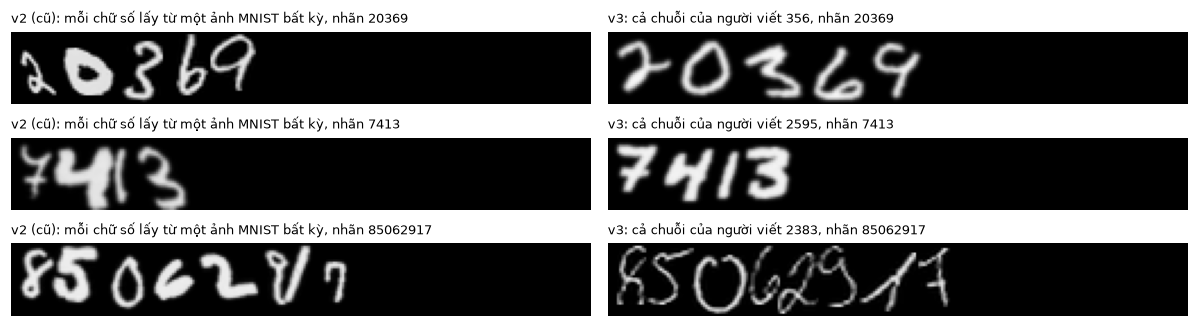

In [5]:
with np.load(os.path.join(TASK3_DIR, "raw", "mnist.npz")) as d:
    x_train, y_train, x_test, y_test = d["x_train"], d["y_train"], d["x_test"], d["y_test"]
WRITERS = gen3.load_writers(y_train, y_test)     # {"train"/"test": (mã người viết, nhóm tờ mẫu) của từng ảnh MNIST}
writer_train, writer_test = WRITERS["train"][0], WRITERS["test"][0]

rng = np.random.default_rng(12)
test_pool = gen3.WriterPool(np.arange(len(x_test)), writer_test, y_test)
any_writer_pools = [np.flatnonzero(y_test == k) for k in range(10)]
examples = ["20369", "7413", "85062917"]

fig, axes = plt.subplots(len(examples), 2, figsize=(11, 0.95 * len(examples) + 0.3))
for r, label in enumerate(examples):
    digits = np.array([int(c) for c in label])
    img_mixed, _ = gen2.make_image(digits, any_writer_pools, x_test, rng)       # cách cũ (v2)
    w, source = test_pool.sample(digits, rng)
    img_same, _ = gen3.make_image([x_test[k] for k in source], rng)          # cách mới (v3)
    for c, (img, title) in enumerate([(img_mixed, f"v2 (cũ): mỗi chữ số lấy từ một ảnh MNIST bất kỳ, nhãn {label}"),
                                      (img_same, f"v3: cả chuỗi của người viết {w}, nhãn {label}")]):
        canvas = np.zeros((32, 256), np.uint8)
        canvas[:, :img.width] = np.asarray(img)
        axes[r, c].imshow(canvas, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(title, fontsize=8.5, loc="left")
        axes[r, c].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "data_writer_comparison.png"), bbox_inches="tight")
plt.show()

## 3. Phân bố độ dài chuỗi và tần suất chữ số

Độ dài chuỗi được chọn đều trong khoảng 3–8 và mỗi chữ số 0–9 được chọn đều, trước khi chọn người viết, nên nhãn không phụ thuộc người viết và không có lớp nào bị lệch (chương 5.3 nêu mất cân bằng lớp là một nguyên nhân làm mô hình dự đoán kém).

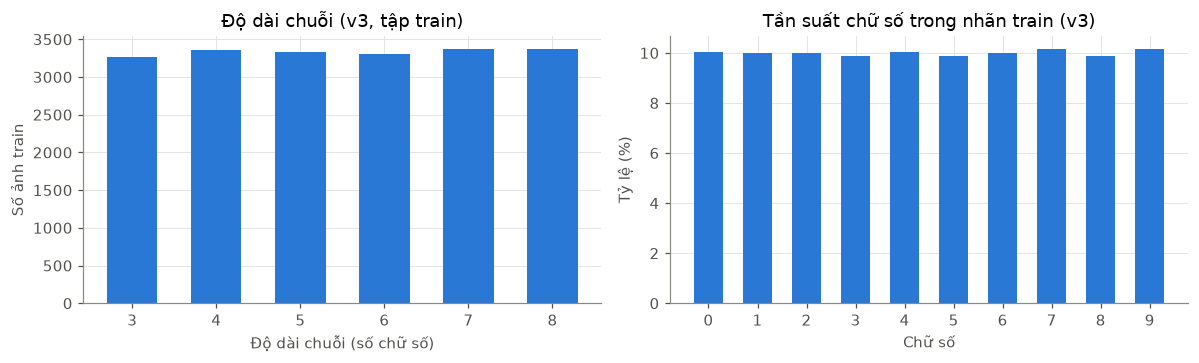

In [6]:
lengths = np.arange(3, 9)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
counts = v3_train["length"].value_counts().reindex(lengths)
axes[0].bar(lengths, counts.values, width=0.6, color=COLORS["v3"])
axes[0].set(xlabel="Độ dài chuỗi (số chữ số)", ylabel="Số ảnh train", title="Độ dài chuỗi (v3, tập train)")

digits = "".join(v3_train["label"])
freq = pd.Series(list(digits)).value_counts().reindex([str(d) for d in range(10)]) / len(digits)
axes[1].bar(np.arange(10), freq.values * 100, width=0.6, color=COLORS["v3"])
axes[1].set(xlabel="Chữ số", ylabel="Tỷ lệ (%)", title="Tần suất chữ số trong nhãn train (v3)", xticks=range(10))
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "data_length_digit_distribution.png"), bbox_inches="tight")
plt.show()

## 4. Bề rộng ảnh theo độ dài chuỗi

Nếu bề rộng ảnh tách hẳn theo độ dài, mô hình có thể đoán số chữ số chỉ bằng cách nhìn chỗ hết nét chữ. Ở v3, các khoảng bề rộng chồng lấn nhiều (bảng dưới hình), nên mô hình phải thực sự đọc từng chữ số. Khoảng bề rộng của v3 còn rộng hơn v2, vì cỡ chữ và khoảng cách được chọn cho cả chuỗi: người viết chữ to, thưa thì cả chuỗi rộng, người viết chữ nhỏ, sát thì cả chuỗi hẹp. Hộp trong hình bao 50% số ảnh ở giữa, râu kéo tới 1,5 lần khoảng tứ phân vị.

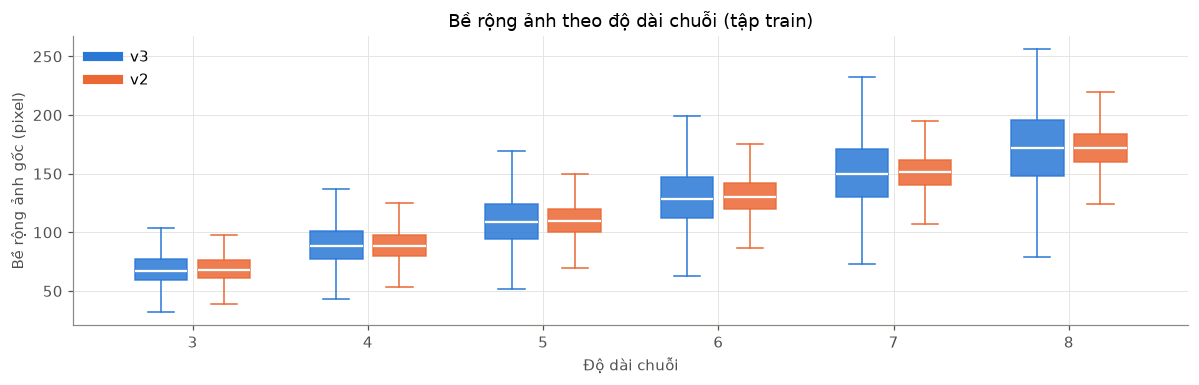

min     median         max     
version   v2  v3     v2     v3   v2   v3
length                                  
3         35  28   68.0   67.0  117  147
4         48  40   88.0   88.0  151  172
5         66  52  110.0  109.0  170  223
6         75  52  130.0  128.0  201  249
7        101  73  151.0  150.0  221  256
8        107  79  172.0  172.0  254  256

In [7]:
train_meta = meta[meta["split"] == "train"]
fig, ax = plt.subplots(figsize=(11, 3.6))
for i, version in enumerate(["v3", "v2"]):
    data = [train_meta[(train_meta["version"] == version) & (train_meta["length"] == n)]["width"] for n in lengths]
    ax.boxplot(data, positions=lengths + (i - 0.5) * 0.36, widths=0.3, patch_artist=True, showfliers=False,
               boxprops=dict(facecolor=COLORS[version], edgecolor=COLORS[version], alpha=0.85),
               medianprops=dict(color="white", linewidth=1.5),
               whiskerprops=dict(color=COLORS[version]), capprops=dict(color=COLORS[version]))
    ax.plot([], [], color=COLORS[version], linewidth=6, label=version)
ax.set(xticks=lengths, xticklabels=lengths, xlabel="Độ dài chuỗi", ylabel="Bề rộng ảnh gốc (pixel)",
       title="Bề rộng ảnh theo độ dài chuỗi (tập train)")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "data_width_by_length.png"), bbox_inches="tight")
plt.show()

width_table = (train_meta.groupby(["version", "length"])["width"].agg(["min", "median", "max"]).unstack(0))
width_table

## 5. Tiền xử lý ảnh: đệm nền đen bên phải, không kéo giãn

Mạng CNN cần ảnh cùng kích thước. Nhóm **đệm thêm nền đen bên phải** cho đủ 32 × 256 thay vì kéo giãn ảnh: kéo giãn làm chữ số béo gầy khác nhau tuỳ độ dài chuỗi (ảnh 3 chữ số bị kéo rộng gấp vài lần). Giá trị điểm ảnh được chia cho 255 để nằm trong khoảng [0, 1]. Hàm `load_task3` trong `data_utils.py` đã làm sẵn việc đệm.

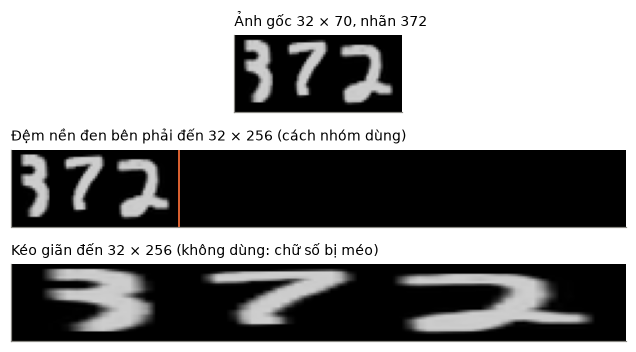

In [8]:
i = int(np.flatnonzero(v3_train["length"].values == 3)[0])
row = v3_train.iloc[i]
original = np.asarray(Image.open(os.path.join(VERSIONS["v3"], row["image_path"])).convert("L"))
stretched = np.asarray(Image.fromarray(original).resize((256, 32), Image.Resampling.BILINEAR))

fig, axes = plt.subplots(3, 1, figsize=(8, 3.3))
axes[0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"Ảnh gốc {original.shape[0]} × {original.shape[1]}, nhãn {row['label']}", fontsize=9, loc="left")
axes[1].imshow(X3[i], cmap="gray", vmin=0, vmax=255)
axes[1].axvline(original.shape[1] - 0.5, color="#eb6834", linewidth=1.2)
axes[1].set_title("Đệm nền đen bên phải đến 32 × 256 (cách nhóm dùng)", fontsize=9, loc="left")
axes[2].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Kéo giãn đến 32 × 256 (không dùng: chữ số bị méo)", fontsize=9, loc="left")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "data_padding.png"), bbox_inches="tight")
plt.show()

## 6. Mã hoá nhãn thành dãy token cho decoder

Decoder sinh lần lượt từng ký hiệu, giống dịch máy ở chương 8. Bộ từ vựng có 13 token: chữ số 0–9 là token 0–9, `<pad>` = 10, `<bos>` = 11 (báo bắt đầu), `<eos>` = 12 (báo kết thúc). Chuỗi dài nhất có 8 chữ số nên mỗi dãy có 8 + 1 = 9 vị trí.

- **Đầu vào decoder** (teacher forcing): `<bos>` d1 … dn, đệm `<pad>` cho đủ 9.
- **Đích cần dự đoán**: d1 … dn `<eos>`, đệm `<pad>`; vị trí `<pad>` bị bỏ qua khi tính hàm mất mát.

In [9]:
TOKEN_NAMES = [str(d) for d in range(10)] + ["<pad>", "<bos>", "<eos>"]
dec_in, dec_out = encode_labels(["20369", "013204"], max_len=8)
pd.DataFrame({"vị trí": range(1, 10),
              "đầu vào '20369'": [TOKEN_NAMES[t] for t in dec_in[0]],
              "đích '20369'": [TOKEN_NAMES[t] for t in dec_out[0]],
              "đầu vào '013204'": [TOKEN_NAMES[t] for t in dec_in[1]],
              "đích '013204'": [TOKEN_NAMES[t] for t in dec_out[1]]}).set_index("vị trí").T

vị trí,1,2,3,4,5,6,7,8,9
đầu vào '20369',<bos>,2,0,3,6,9,<pad>,<pad>,<pad>
đích '20369',2,0,3,6,9,<eos>,<pad>,<pad>,<pad>
đầu vào '013204',<bos>,0,1,3,2,0,4,<pad>,<pad>
đích '013204',0,1,3,2,0,4,<eos>,<pad>,<pad>


In [10]:
# Giải mã ngược: dừng ở <eos>, giữ nguyên số 0 ở đầu
print(decode_tokens(dec_out[0]), decode_tokens(dec_out[1]))

20369 013204


## 7. Tăng cường dữ liệu (data augmentation, chương 5.3)

Khi huấn luyện, mỗi batch được biến đổi ngẫu nhiên lại: đổi độ sáng (nhân hệ số 0,8–1,1) và thêm nhiễu Gauss. Nhãn không đổi. Nhờ vậy mô hình gần như không thấy cùng một ảnh hai lần, giảm học vẹt.

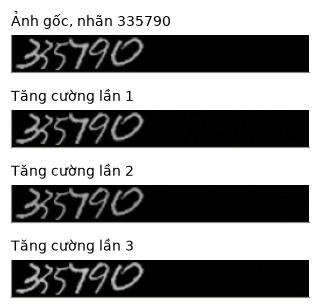

In [11]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(4, 1, figsize=(7, 2.9))
axes[0].imshow(X3[0], cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"Ảnh gốc, nhãn {labels3[0]}", fontsize=9, loc="left")
for k in range(1, 4):
    axes[k].imshow(augment(X3[:1], rng)[0], cmap="gray", vmin=0, vmax=255)
    axes[k].set_title(f"Tăng cường lần {k}", fontsize=9, loc="left")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "data_augmentation.png"), bbox_inches="tight")
plt.show()

## 8. Kiểm tra: cùng một người viết, không rò rỉ giữa các tập

Ô dưới kiểm tra lại bộ v3 bằng mã người viết của QMNIST, độc lập với script sinh:
1. Mọi chữ số trong một ảnh là chữ của đúng người viết ghi ở cột `writer`.
2. Các ảnh MNIST nguồn (cột `source`) đúng là các chữ số của nhãn, theo đúng thứ tự.
3. **Không người viết nào xuất hiện ở hai tập.** Nếu chữ của cùng một người có cả trong train lẫn test, mô hình có thể quen nét chữ người đó và điểm test bị thổi phồng. MNIST vốn đã tách người viết giữa MNIST-train và MNIST-test; nhóm chia tiếp người viết của MNIST-train: 20% số người viết (chọn ngẫu nhiên trong từng nhóm tờ mẫu NIST) chỉ dùng cho validation. Vì vậy validation và test đều là chữ của người mà mô hình chưa gặp khi huấn luyện.

In [12]:
rows, writer_sets = [], {}
for split in SPLITS:
    df = v3[v3["split"] == split]
    writer_of = writer_test if split == "test" else writer_train      # train, validation lấy từ MNIST-train
    digit_of = y_test if split == "test" else y_train
    sources = [np.array(s.split(), dtype=int) for s in df["source"]]
    rows.append({"tập": split, "số ảnh": len(df),
                 "mọi chữ số cùng một người viết": sum(bool(np.all(writer_of[s] == w)) for s, w in zip(sources, df["writer"])),
                 "ảnh nguồn đúng nhãn": sum("".join(map(str, digit_of[s])) == lab for s, lab in zip(sources, df["label"])),
                 "số người viết": df["writer"].nunique()})
    writer_sets[split] = set(df["writer"])
display(pd.DataFrame(rows).set_index("tập"))

for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    print(f"Người viết chung giữa {a} và {b}: {len(writer_sets[a] & writer_sets[b])}")
split_ids = np.load(os.path.join(VERSIONS["v3"], "source_split_indices.npz"))
print("Ảnh MNIST-train dành cho train:", len(split_ids["train_indices"]),
      "| dành cho validation:", len(split_ids["validation_indices"]),
      "| dùng chung:", len(np.intersect1d(split_ids["train_indices"], split_ids["validation_indices"])))

,số ảnh,mọi chữ số cùng một người viết,ảnh nguồn đúng nhãn,số người viết
tập,,,,
train,20000,20000,20000,431
validation,2000,2000,2000,108
test,2000,2000,2000,276


Người viết chung giữa train và validation: 0
Người viết chung giữa train và test: 0
Người viết chung giữa validation và test: 0
Ảnh MNIST-train dành cho train: 47790 | dành cho validation: 12210 | dùng chung: 0


## 9. Người viết trong từng tập

NIST thu chữ của hai nhóm người: nhân viên Cục Điều tra Dân số Mỹ (mã người viết nhỏ hơn 2100) và học sinh trung học (mã từ 2100 trở lên). Chữ học sinh được coi là khó đọc hơn hẳn. MNIST trộn cả hai nhóm vào cả tập train lẫn tập test.

In [13]:
v3["nhóm người viết"] = np.where(v3["writer"] >= 2100, "học sinh", "nhân viên")
per_writer = v3.groupby(["split", "writer"]).size()
writer_table = pd.DataFrame({
    "số người viết": v3.groupby("split")["writer"].nunique(),
    "số ảnh mỗi người viết (trung vị)": per_writer.groupby("split").median(),
    "số ảnh mỗi người viết (nhiều nhất)": per_writer.groupby("split").max(),
    "tỷ lệ ảnh của học sinh": v3.groupby("split")["nhóm người viết"].apply(lambda s: (s == "học sinh").mean()),
}).reindex(SPLITS)
display(writer_table.round(3))

# Số chữ số MNIST-test của mỗi người viết, theo nhóm
digits_per_writer = pd.Series(writer_test).value_counts()
print("MNIST-test, số chữ số mỗi người viết (trung vị):",
      {"nhân viên": int(digits_per_writer[digits_per_writer.index < 2100].median()),
       "học sinh": int(digits_per_writer[digits_per_writer.index >= 2100].median())})
test_meta = v3[v3["split"] == "test"]
(test_meta.groupby("length")["nhóm người viết"].apply(lambda s: (s == "học sinh").mean())
          .rename("tỷ lệ ảnh test của học sinh").to_frame().T.round(2))

,số người viết,số ảnh mỗi người viết (trung vị),số ảnh mỗi người viết (nhiều nhất),tỷ lệ ảnh của học sinh
split,,,,
train,431,46.0,64,0.471
validation,108,19.0,29,0.468
test,276,6.0,28,0.648


MNIST-test, số chữ số mỗi người viết (trung vị): {'nhân viên': 107, 'học sinh': 20}


length,3,4,5,6,7,8
tỷ lệ ảnh test của học sinh,0.81,0.71,0.66,0.62,0.57,0.53


**Nhận xét.**
- Mọi người viết của MNIST-train đều xuất hiện trong ảnh train hoặc validation. Ở tập test, phần lớn người viết của MNIST-test được dùng; những người còn lại có quá ít chữ số.
- Ở MNIST-test, mỗi học sinh chỉ viết khoảng 20 chữ số (khoảng 2 chữ số cho mỗi loại 0–9), còn mỗi nhân viên khoảng 100. Một chuỗi dài, nhất là chuỗi có chữ số lặp lại, cần nhiều mẫu của cùng một người, nên chuỗi test dài thường lấy từ nhân viên hơn: tỷ lệ ảnh của học sinh giảm dần khi chuỗi dài ra (bảng trên). Cần nhớ điều này khi so độ chính xác giữa các độ dài ở notebook 05.

## 10. Tóm tắt cho mục 3.1 của báo cáo

| Mục | Nội dung |
|---|---|
| Nội dung ảnh | Dãy 3–8 chữ số viết tay, ghép từ MNIST, **mọi chữ số của một ảnh do cùng một người viết** (mã người viết theo QMNIST); chữ trắng trên nền đen |
| Số ảnh | 24.000 ảnh: 20.000 train / 2.000 validation / 2.000 test (thêm bộ 60.000 ảnh train cho thí nghiệm sinh thêm dữ liệu) |
| Kích thước, định dạng | PNG ảnh xám 8 bit, cao 32 pixel, rộng 28–256 pixel; đệm phải thành 32 × 256 khi đưa vào mô hình |
| Nhãn | Chuỗi chữ số (giữ số 0 ở đầu), ví dụ `"013204"`; mã hoá thành 9 token với `<bos>`, `<eos>`, `<pad>` |
| Chia tập | Theo người viết: 431 người viết cho train, 108 người khác cho validation, test dùng người viết của MNIST-test; không người viết nào xuất hiện ở hai tập |